In [120]:
# !pip install tensorflow matplotlib
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import matplotlib.pyplot as plt
import random
from tensorflow.keras.preprocessing.image import ImageDataGenerator
import numpy as np

In [121]:
# Define the paths to the training and testing data directories
# D:\Eng\B.E\DL\deepLearning\dataset\cifar-10-img\cifar-10-img\train
train_data_dir = 'dataset/cifar-10-img/cifar-10-img/train'
test_data_dir = 'dataset/cifar-10-img/cifar-10-img/test'

In [122]:
# Set up an ImageDataGenerator to rescale pixel values to [0, 1]
image_data_generator = ImageDataGenerator(rescale=1.0/255)

# Define batch sizes
train_batch_size = 20000
test_batch_size = 2000

# Create data generators for training and testing
train_generator = image_data_generator.flow_from_directory(
    train_data_dir,
    target_size=(32, 32),  # Resize images to 28x28 pixels
    batch_size=train_batch_size,  # Number of images per training batch
    class_mode='categorical',  # One-hot encoded labels
    shuffle=True,  # Shuffle the order of images during training
)

test_generator = image_data_generator.flow_from_directory(
    test_data_dir,
    target_size=(32, 32),  # Resize images to 28x28 pixels
    batch_size=test_batch_size,  # Number of images per testing batch
    class_mode='categorical',  # One-hot encoded labels
    shuffle=True,  # Shuffle the order of images during testing
)

Found 40079 images belonging to 10 classes.
Found 9921 images belonging to 10 classes.


In [123]:
x_train, y_train = train_generator[0]
x_test, y_test = test_generator[0]

In [124]:
print(f"Shape of X_train {x_train.shape}")
print(f"Shape of y_train {y_train.shape}")
print(f"Shape of x_test  {x_test.shape}")
print(f"Shape of y_test  {y_test.shape}")

Shape of X_train (20000, 32, 32, 3)
Shape of y_train (20000, 10)
Shape of x_test  (2000, 32, 32, 3)
Shape of y_test  (2000, 10)


In [125]:
num_classes = 10
class_names = ['airplane','automobile','bird','cat','deer',
               'dog','frog','horse','ship','truck']

In [126]:
x_train.shape[1:]

(32, 32, 3)

In [127]:
# # Create a pure Feedforward Neural Network
# model = keras.Sequential([
#     keras.Input(shape=(32, 32, 3)),

#     layers.Flatten(),

#     layers.Dense(512, activation='relu'),
#     layers.Dense(256, activation='relu'),
#     layers.Dense(128, activation='relu'),

#     layers.Dense(10, activation='softmax')
# ])

# Create a list of layers
model = keras.Sequential([
    keras.Input(shape=(32, 32, 3)),
    layers.Conv2D(32, (3, 3), activation='relu'),
    layers.BatchNormalization(),
    layers.Conv2D(32, (3, 3), activation='relu'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),
    
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),
    
    layers.Conv2D(128, (3, 3), activation='relu'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),
    
    layers.Flatten(),
    layers.Dense(512, activation='relu'),
    layers.Dropout(0.2),
    
    layers.Dense(512, activation='relu'),
    layers.Dropout(0.2),
    
    layers.Dense(10, activation='softmax')
])

In [128]:
from tensorflow.keras.optimizers import SGD
# Compile the model
sgd_optimizer = SGD(learning_rate=0.01)

model.compile(optimizer=sgd_optimizer, loss='categorical_crossentropy', metrics=['accuracy'])

# Training the model
history = model.fit(x_train, y_train,
              batch_size=20,
              epochs=10,
              validation_data=(x_test, y_test),
              shuffle=True)

Epoch 1/10
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 10s 10ms/step - accuracy: 0.3954 - loss: 1.6818 - val_accuracy: 0.4830 - val_loss: 1.3962
Epoch 2/10
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 10s 10ms/step - accuracy: 0.5321 - loss: 1.3104 - val_accuracy: 0.5595 - val_loss: 1.2451
Epoch 3/10
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 10s 10ms/step - accuracy: 0.5942 - loss: 1.1514 - val_accuracy: 0.6245 - val_loss: 1.0877
Epoch 4/10
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 10s 10ms/step - accuracy: 0.6425 - loss: 1.0197 - val_accuracy: 0.6130 - val_loss: 1.0788
Epoch 5/10
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 10s 10ms/step - accuracy: 0.6787 - loss: 0.9159 - val_accuracy: 0.6565 - val_loss: 0.9958
Epoch 6/10
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 10s 10ms/step - accuracy: 0.7096 - loss: 0.8212 - val_accuracy: 0.6710 - val_loss: 0.9385
Epoch 7/10
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 10s 10ms/step - accuracy: 0.7345 - loss: 0.7559 - val_accuracy: 0.6830 - val_loss: 0.9178
Epoch 8/10
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 10s 10ms/step - accuracy: 0.7621 -

<Axes: >

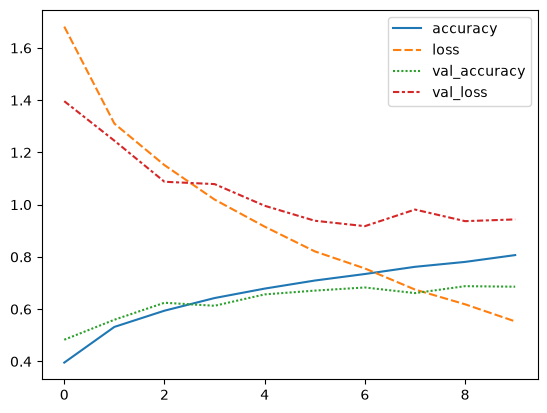

In [129]:
import seaborn as sns
sns.lineplot(model.history.history)

In [130]:
test_loss, test_acc = model.evaluate(x_test, y_test)
print("Loss: ", test_loss)
print("Accuracy: ", test_acc)

63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.6860 - loss: 0.9436
Loss:  0.9435640573501587
Accuracy:  0.6859999895095825


63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step


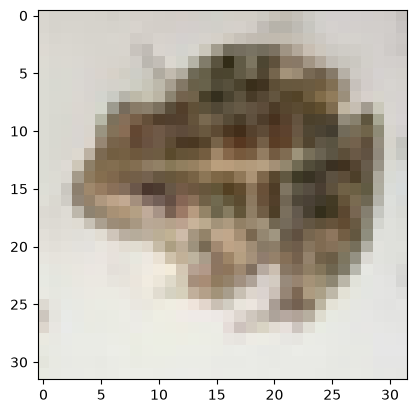

frog


In [131]:
predicted_value=model.predict(x_test)
plt.imshow(x_test[50])
plt.show()
print(class_names[np.argmax(predicted_value[50], axis=0)])